In [1]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import random
import numpy as np
import pandas as pd
import torch
import optuna
import protein_ss.dataset as ss_dataset
import protein_ss.plots as ss_plots
import protein_ss.modeling.classes as ss_classes
import protein_ss.modeling.train as ss_train
import protein_ss.modeling.predict as ss_predict

from IPython.display import display
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

SEED = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(DEVICE)

cuda


In [2]:
MAX_LEN = 512
MAX_TRAIN = 3000 # 2000 for train split, 1000 for val split

train_df = ss_dataset.download('training_hhblits.csv')
test_df = ss_dataset.download('CB513.csv')
display(train_df.head(5))
display(test_df.head(5))

train_df = ss_dataset.clean(train_df, MAX_LEN, SEED, MAX_TRAIN)
test_df = ss_dataset.clean(test_df, MAX_LEN, SEED)
print(train_df.shape)
print(test_df.shape)

all_labels = ''.join(train_df['dssp3']) # join all target sequences into 1 contiguous str
counts = pd.Series(list(all_labels)).value_counts() # split characters in contiguous str into list of elements -> convert to Series -> value_counts for count dist of state labels
freq = counts / counts.sum() # express int proportions
baseline = freq.max() # store baseline performance benchmark

display(freq) # majority class baseline performance benchmark: C at 0.420512

,input,dssp3,dssp8,disorder,cb513_mask
0,MKTAYIAKQRQISFVKSHFSRQLEERLGLIEVQAPILSRVGDGTQD...,CCCCHHHHHHHHHHHHHHHHHHHHHHHCEEECCCCCEEECCCCCCC...,CCCCHHHHHHHHHHHHHHHHHHHHHHHCEEECCCCSEEETTSSCSC...,0.0 0.0 0.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
1,SRMPSPPMPVPPAALFNRLLDDLGFSAGPALCTMLDTWNEDLFSAL...,CCCCCCCCCCCHHHHHHHHHHHHCCCCHHHHHHHHHHCCCCCCCCC...,CCSCCCCCCCCHHHHHHHHHHHHTCTTHHHHHHHHHHCCCCCSTTS...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
2,RRSPPADAIPKSKKVKVSHRSHSTEPGLVLTLGQGDVGQLGLGENV...,CCCCCCCCCCCCCCCCCCCCCCCCCCEEEEEEEECCCCCCCCCCCC...,CCCCCCCCCCCCCCCCCCCTTCCCCCBEEEEEEECTTSTTCSCTTC...,0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
3,GSAGEDVGAPPDHLWVHQEGIYRDEYQRTWVAVVEEETSFLRARVQ...,CCCCCCCCCCCCEEEEEECCEEEECCCCEEEEEEEECCCCEEEEEE...,CCCCCCCCCCCSEEEEEETTEEEETTSCEEEEEEEECSSCEEEEEE...,0.0 0.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
4,GDEEKRNRAITARRQHLKSVMLQIAATELEKEEGRREAEKQNYLAEH,CCCCHHHHHHHHHHHHHHHHHHHHHHHHHHHCCCCCCCCCCCCCCCC,CCCCHHHHHHHHHHHHHHHHHHHHHHHHHHHTCCCCCCCCCCCCCCC,0.0 0.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....


,input,dssp3,dssp8,disorder,cb513_mask
0,RTDCYGNVNRIDTTGASCKTAKPEGLSYCGVSASKKIAERDLQAMD...,CCCCCCCHHHCCCCCECHHHHCCCCCCCCEHHHHHHHHHHCHHHHH...,CCCTTCCGGGSCCCCBCHHHHTTTTCSCCBHHHHHHHHHHTHHHHH...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
1,GKITFYEDRGFQGRHYECSSDHSNLQPYFSRCNSIRVDSGCWMLYE...,CEEEEEEECCCEEEEEEECCCECCCCCCCCCCCEEEEEECEEEEEC...,CEEEEEEETTTEEEEEEECSCBSCCTTTCSCCSEEEEEESEEEEES...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
2,MFKVYGYDSNIHKCVYCDNAKRLLTVKKQPFEFINIMPEKGVFDDE...,CEEEEECCCCCCCCHHHHHHHHHHHHCCCCEEEEECCCECCECCHH...,CEEEEECCTTTSCCHHHHHHHHHHHHTTCCEEEEESCSBTTBCCHH...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
3,APAFSVSPASGASDGQSVSVSVAAAGETYYIAQCAPVGGQDACNPA...,CCEEEEECCCCCCCCCEEEEEEECCCCEEEEEEECEECCEECCCCC...,CCEEEEECCSSCCSSCEEEEEEESCCSEEEEEEECEETTEECCCTT...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....
4,TPAFNKPKVELHVHLDGAIKPETILYFGKKRGIALPADTVEELRNI...,CCCCCCCEEEEEEEHHHCCCHHHHHHHHHHHCCCCCCCCHHHHHHH...,CCSCCSCEEEEEEEGGGSCCHHHHHHHHHHHTCCCSCSSHHHHHHH...,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....,1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1.0 1....


(3000, 2)
(443, 2)


C    0.420512
H    0.362535
E    0.216953
Name: count, dtype: float64

In [3]:
EPOCHS = 40
BATCH_SIZE = 32
AA = 'ACDEFGHIKLMNPQRSTVWY' # standard IUPAC letter for all 20 amino acids
AA_TO_IDX = {a:i for i, a in enumerate(AA)} # tokenizer mapping AA letter to index following 0-based indexing
X_IDX = 20 # index unk residues
N_VOCAB = len(AA_TO_IDX)# 20; excludes unk residue X, mask or pad

PAD_IDX = 21 # index for padding tokens
MASK_IDX = 22
MLM_VOCAB = N_VOCAB + 3 # 23; 20 standard residues + unk X residue + 1 padding + 1 mask

LABELS = ''.join(freq.index)
LABELS_TO_IDX = {s: i for i, s in enumerate(LABELS)}
IGNORE_IDX = -100

In [4]:
train_split, val_split = train_test_split(train_df, test_size=1/3, random_state=SEED, shuffle=True) # expect 2000 train examples, 1000 val examples
generator = torch.Generator().manual_seed(SEED) # cpu generator

train_dataset = ss_dataset.MLMDataset(train_split, AA_TO_IDX, X_IDX)
val_dataset = ss_dataset.MLMDataset(val_split, AA_TO_IDX, X_IDX)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=lambda batch: ss_dataset.mlm_collate(batch, PAD_IDX, IGNORE_IDX, MASK_IDX, X_IDX, n_vocab=N_VOCAB))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=lambda batch: ss_dataset.mlm_collate(batch, PAD_IDX, IGNORE_IDX, MASK_IDX, X_IDX, generator, n_vocab=N_VOCAB))

In [5]:
study = optuna.create_study(direction='maximize', pruner=optuna.pruners.MedianPruner(n_warmup_steps=5))
study.optimize(lambda trial:ss_train.objective(trial, train_loader, val_loader, MAX_LEN, MLM_VOCAB, EPOCHS, PAD_IDX, IGNORE_IDX, SEED, DEVICE, generator, n_vocab=N_VOCAB), n_trials=20)
best_params = study.best_params
print(f"Best Masked Token Accuracy was {study.best_value:.3f} from hyperparameter set: {best_params}")

[I 2026-10-31 08:55:17,076] A new study created in memory with name: no-name-93f4fa12-b68d-4821-a0ec-53de127a0e2a
c:\Users\Admin\Desktop\Course_Materials\protein_ss_mlm\.venv\Lib\site-packages\torch\autograd\graph.py:841: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\transformers\cuda\attention_backward.cu:899.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
[I 2026-10-31 08:57:13,890] Trial 0 finished with value: 0.190042182803154 and parameters: {'d_model': 256, 'nhead': 2, 'num_layers': 2, 'lr': 0.0009830478533936773, 'dropout': 0.22979498432463086}. Best is trial 0 with value: 0.190042182803154.
[I 2026-10-31 08:59:14,292] Trial 1 finished with value: 0.19414211809635162 and parameters: {'d_model': 256

Best Masked Token Accuracy was 0.194 from hyperparameter set: {'d_model': 256, 'nhead': 4, 'num_layers': 4, 'lr': 0.000653045539964156, 'dropout': 0.009484521142531878}


Epochs:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch: 1
	Train Loss: 2.760
	Val Loss: 2.731
	Masked Token Accuracy: 0.178

Epoch: 5
	Train Loss: 2.692
	Val Loss: 2.697
	Masked Token Accuracy: 0.184

Epoch: 10
	Train Loss: 2.682
	Val Loss: 2.691
	Masked Token Accuracy: 0.182

Epoch: 15
	Train Loss: 2.673
	Val Loss: 2.684
	Masked Token Accuracy: 0.189

Epoch: 20
	Train Loss: 2.668
	Val Loss: 2.678
	Masked Token Accuracy: 0.191

Epoch: 25
	Train Loss: 2.664
	Val Loss: 2.667
	Masked Token Accuracy: 0.194

Epoch: 30
	Train Loss: 2.651
	Val Loss: 2.665
	Masked Token Accuracy: 0.194

Epoch: 35
	Train Loss: 2.653
	Val Loss: 2.662
	Masked Token Accuracy: 0.195

Epoch: 40
	Train Loss: 2.650
	Val Loss: 2.661
	Masked Token Accuracy: 0.195



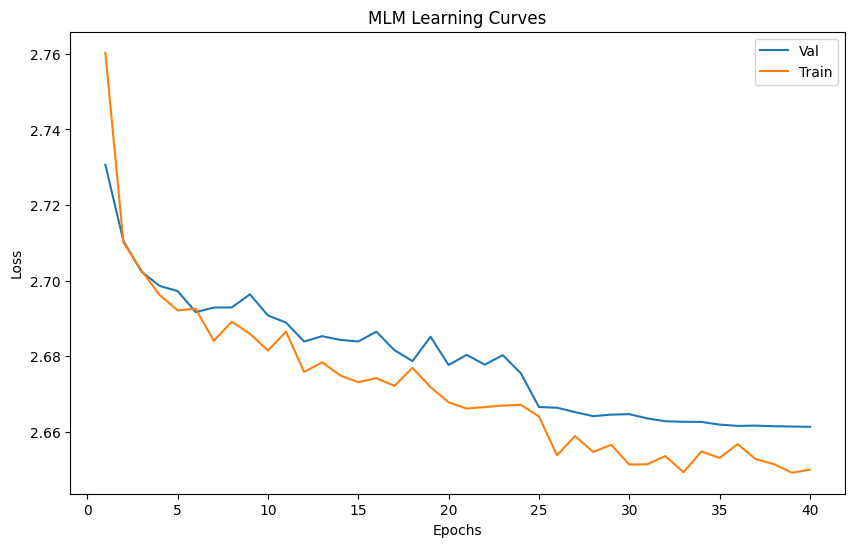

Best Epoch: 39
	Train Loss: 2.649
	Val Loss: 2.661
	Best Masked Token Accuracy: 0.195


In [6]:
out_dict = ss_train.train_val_loop(train_loader, val_loader, **best_params, max_len=MAX_LEN, mlm_vocab=MLM_VOCAB, epochs=EPOCHS, padding_idx=PAD_IDX, ignore_idx=IGNORE_IDX, seed=SEED, device=DEVICE, generator=generator, n_vocab=N_VOCAB)
train_epoch_losses = out_dict['train_epoch_losses']
val_epoch_losses = out_dict['val_epoch_losses']
best_epoch = out_dict['best_epoch']
best_eval_metric = out_dict['best_eval_metric']
encoder = out_dict['model']

ss_plots.plot_learning_curves(train_epoch_losses, val_epoch_losses, 'MLM Learning Curves')
print(f"Best Epoch: {best_epoch + 1}\n\tTrain Loss: {train_epoch_losses[best_epoch]:.3f}\n\tVal Loss: {val_epoch_losses[best_epoch]:.3f}\n\tBest Masked Token Accuracy: {best_eval_metric:.3f}")

In [7]:
ss_train_dataset = ss_dataset.SecondaryStructureDataset(train_split, AA_TO_IDX, LABELS_TO_IDX, IGNORE_IDX, X_IDX)
ss_val_dataset = ss_dataset.SecondaryStructureDataset(val_split, AA_TO_IDX, LABELS_TO_IDX, IGNORE_IDX, X_IDX)

ss_train_loader = DataLoader(ss_train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=lambda batch: ss_dataset.collate(batch, PAD_IDX, IGNORE_IDX))
ss_val_loader = DataLoader(ss_val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=lambda batch: ss_dataset.collate(batch, PAD_IDX, IGNORE_IDX))

In [8]:
all_train_labels = ''.join(train_split['dssp3']) # training labels only!
all_label_idx = np.array([LABELS_TO_IDX[label] for label in list(all_train_labels)], dtype=np.int64)
class_weights = compute_class_weight(class_weight='balanced', classes=np.arange(len(LABELS)), y=all_label_idx)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
frozen_encoder = ss_classes.FrozenMLMEncoder(encoder).to(DEVICE) # always set to eval mode

In [9]:
cnn_bilstm_study = optuna.create_study(direction='maximize', pruner=optuna.pruners.MedianPruner(n_warmup_steps=5))
cnn_bilstm_study.optimize(lambda trial: ss_train.cnn_bilstm_objective(trial, ss_train_loader, ss_val_loader, weights_tensor, frozen_encoder, EPOCHS, IGNORE_IDX, SEED, DEVICE, len(LABELS)), n_trials=20)
cnn_bilstm_best_params = cnn_bilstm_study.best_params
print(f"Best MCC was {cnn_bilstm_study.best_value:.3f} from hyperparameter set: {cnn_bilstm_best_params}")

[I 2026-10-31 09:49:17,086] A new study created in memory with name: no-name-4391ae9b-5f2b-4729-a94e-61f339129a15
[I 2026-10-31 09:54:15,069] Trial 0 finished with value: 0.5305790305137634 and parameters: {'kernel_size': 7, 'hidden_size': 32, 'conv_layers': 2, 'lr': 0.0003463660560130893, 'dropout': 0.2584001559681406, 'weight_decay': 0.0006952707814227141}. Best is trial 0 with value: 0.5305790305137634.
[I 2026-10-31 09:59:10,643] Trial 1 finished with value: 0.5368943214416504 and parameters: {'kernel_size': 7, 'hidden_size': 64, 'conv_layers': 1, 'lr': 0.0012192577613088789, 'dropout': 0.20753443909659858, 'weight_decay': 0.005875144127845088}. Best is trial 1 with value: 0.5368943214416504.
[I 2026-10-31 10:04:07,819] Trial 2 finished with value: 0.5343878269195557 and parameters: {'kernel_size': 7, 'hidden_size': 32, 'conv_layers': 2, 'lr': 0.000707550664853217, 'dropout': 0.38016768916338123, 'weight_decay': 0.0034579886373989626}. Best is trial 1 with value: 0.5368943214416504

Best MCC was 0.550 from hyperparameter set: {'kernel_size': 5, 'hidden_size': 64, 'conv_layers': 2, 'lr': 0.001596094995485896, 'dropout': 0.42159555465168425, 'weight_decay': 9.94860737122355e-05}


Epochs:   0%|          | 0/40 [00:00<?, ?it/s]

Epoch: 1
	Train Loss: 0.913
	Val Loss: 0.818
	Val MCC: 0.449
	Val Acc: 0.635

Epoch: 5
	Train Loss: 0.766
	Val Loss: 0.732
	Val MCC: 0.508
	Val Acc: 0.673

Epoch: 10
	Train Loss: 0.724
	Val Loss: 0.707
	Val MCC: 0.532
	Val Acc: 0.694

Epoch: 15
	Train Loss: 0.702
	Val Loss: 0.704
	Val MCC: 0.525
	Val Acc: 0.681

Epoch: 20
	Train Loss: 0.694
	Val Loss: 0.703
	Val MCC: 0.528
	Val Acc: 0.679

Epoch: 25
	Train Loss: 0.685
	Val Loss: 0.699
	Val MCC: 0.536
	Val Acc: 0.689

Epoch: 30
	Train Loss: 0.676
	Val Loss: 0.697
	Val MCC: 0.545
	Val Acc: 0.700

Epoch: 35
	Train Loss: 0.666
	Val Loss: 0.683
	Val MCC: 0.543
	Val Acc: 0.695

Epoch: 40
	Train Loss: 0.664
	Val Loss: 0.681
	Val MCC: 0.549
	Val Acc: 0.702



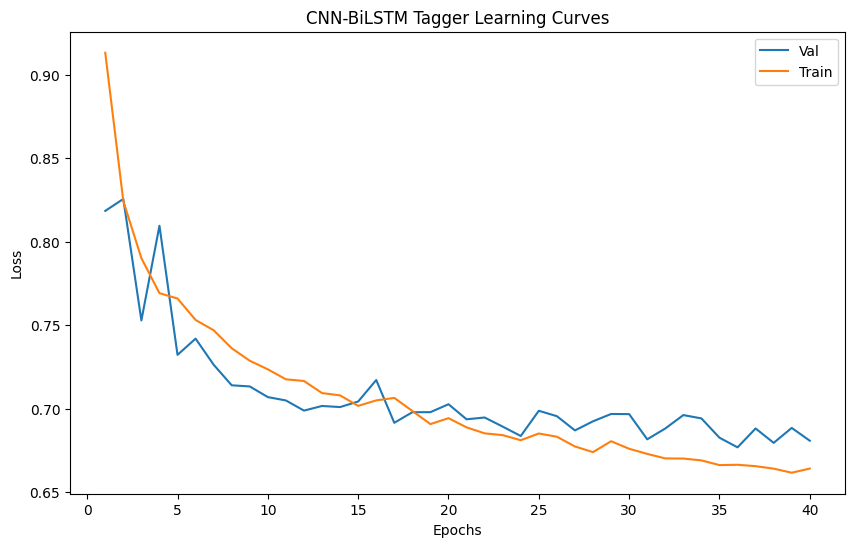

Best Epoch: 36
	Train Loss: 0.666
	Val Loss: 0.677
	Best MCC: 0.549
	Best Epoch Acc: 0.702



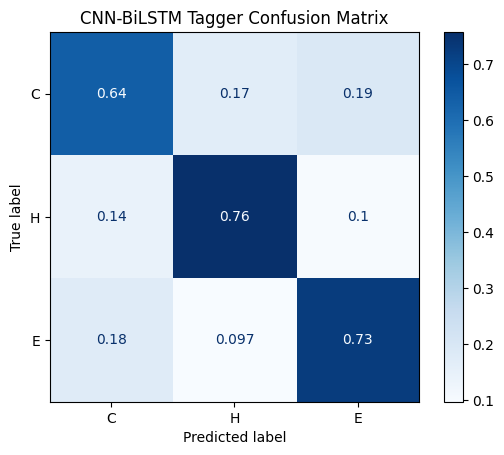

              precision    recall  f1-score   support

           C       0.75      0.64      0.69     95860
           H       0.75      0.76      0.75     81836
           E       0.58      0.73      0.64     49853

    accuracy                           0.70    227549
   macro avg       0.69      0.71      0.70    227549
weighted avg       0.71      0.70      0.70    227549



In [10]:
cnn_bilstm_out_dict = ss_train.cnn_bilstm_train_val_loop(ss_train_loader, ss_val_loader, weights_tensor, frozen_encoder, EPOCHS, IGNORE_IDX, DEVICE, **cnn_bilstm_best_params, num_classes=len(LABELS))
cnn_bilstm_train_epoch_losses = cnn_bilstm_out_dict['train_epoch_losses']
cnn_bilstm_val_epoch_losses = cnn_bilstm_out_dict['val_epoch_losses']
cnn_bilstm_best_epoch = cnn_bilstm_out_dict['best_epoch']
cnn_bilstm_best_eval_metric = cnn_bilstm_out_dict['best_eval_metric']
cnn_bilstm_best_epoch_acc = cnn_bilstm_out_dict['best_epoch_acc']
cnn_bilstm_best_true = cnn_bilstm_out_dict['best_true']
cnn_bilstm_best_preds = cnn_bilstm_out_dict['best_preds']
cnn_bilstm_model = cnn_bilstm_out_dict['model']

ss_plots.plot_learning_curves(cnn_bilstm_train_epoch_losses, cnn_bilstm_val_epoch_losses, 'CNN-BiLSTM Tagger Learning Curves')
print(f"Best Epoch: {cnn_bilstm_best_epoch + 1}\n\tTrain Loss: {cnn_bilstm_train_epoch_losses[cnn_bilstm_best_epoch]:.3f}\n\tVal Loss: {cnn_bilstm_val_epoch_losses[cnn_bilstm_best_epoch]:.3f}\n\tBest MCC: {cnn_bilstm_best_eval_metric:.3f}\n\tBest Epoch Acc: {cnn_bilstm_best_epoch_acc:.3f}\n")

ss_plots.cm_and_class_report(cnn_bilstm_best_true, cnn_bilstm_best_preds, LABELS_TO_IDX, 'CNN-BiLSTM Tagger Confusion Matrix')

Test Set MCC: 0.525
Test Set Acc: 0.685



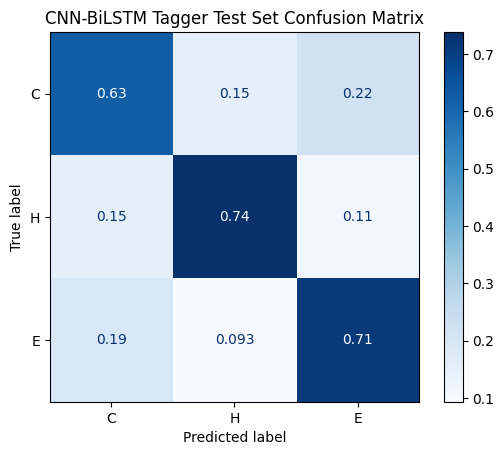

              precision    recall  f1-score   support

           C       0.74      0.63      0.68     43402
           H       0.75      0.74      0.74     34843
           E       0.53      0.71      0.61     21512

    accuracy                           0.68     99757
   macro avg       0.68      0.69      0.68     99757
weighted avg       0.70      0.68      0.69     99757



In [11]:
ss_test_dataset = ss_dataset.SecondaryStructureDataset(test_df, AA_TO_IDX, LABELS_TO_IDX, IGNORE_IDX, X_IDX)
ss_test_loader = DataLoader(ss_test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=lambda batch: ss_dataset.collate(batch, PAD_IDX, IGNORE_IDX))
ss_predict.cnn_bilstm_eval(cnn_bilstm_model, ss_test_loader, IGNORE_IDX, LABELS_TO_IDX, DEVICE, ss_plots.cm_and_class_report, 'CNN-BiLSTM Tagger Test Set Confusion Matrix', len(LABELS))